# Data Analyst Course — Week 4 Capstone Project
## End-to-End Sales Analysis: Cleaning → EDA → SQL/Pandas → Regression → Insights

**Dataset:** "Financial Sample" (700 orders, Sep 2013 – Dec 2014) supplied as a Google Sheet.
**Business question:** *Where do sales and profit come from, what is eroding profit, and which
drivers can we use to predict sales?*

**Workflow**
1. Clean and explore the dataset in Python
2. Exploratory Data Analysis (EDA)
3. Analyse the data with SQL (SQLite) and Pandas
4. Regression model to predict sales
5. Findings & recommendations (summary also provided in the PDF report and Excel workbook)

In [1]:
import json, sqlite3, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

FIG = Path("outputs/figures"); FIG.mkdir(parents=True, exist_ok=True)
Path("data").mkdir(exist_ok=True)

# one consistent, colour-blind-safe palette used for every chart
BLUE, ORANGE, TEAL, RED, GREY = "#2B6CB0", "#DD8452", "#2A9D8F", "#C0392B", "#8A8F98"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.titlesize": 12, "axes.titleweight": "bold",
                                     "axes.labelsize": 10, "figure.dpi": 110})

def money_m(x, _=None):  return f"${x/1e6:,.0f}M"
def money_k(x, _=None):  return f"${x/1e3:,.0f}K"
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight"); plt.show()

## 1. Load & inspect the raw data
The sheet was exported to PDF, so it was first rebuilt into a table with `src/extract_data.py` (columns split by position, truncated text such as *"Governmen"* / *"United Sta"* restored).

In [2]:
# keep_default_na=False because 'None' is a real Discount Band category, not a missing value
raw = pd.read_csv("data/raw_extracted.csv", keep_default_na=False, na_values=[""])
print("Shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype").T)
print("\nMissing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])

Shape: (700, 16)


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,None,"1,513.00",3.00,350.00,"529,550.00",0.00,"529,550.00","393,380.00","136,170.00",1-Dec-14,12,December,2014
1,Government,Germany,Paseo,None,"1,006.00",10.00,350.00,"352,100.00",0.00,"352,100.00","261,560.00","90,540.00",1-Jun-14,6,June,2014
2,Government,Canada,Paseo,None,"1,725.00",10.00,350.00,"603,750.00",0.00,"603,750.00","448,500.00","155,250.00",1-Nov-13,11,November,2013
3,Government,Germany,Paseo,None,"1,513.00",10.00,350.00,"529,550.00",0.00,"529,550.00","393,380.00","136,170.00",1-Dec-14,12,December,2014
4,Government,Germany,Velo,None,"1,006.00",120.00,350.00,"352,100.00",0.00,"352,100.00","261,560.00","90,540.00",1-Jun-14,6,June,2014


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
dtype,str,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,str,int64,str,int64



Missing values per column:
Sales    1
COGS     1
dtype: int64


## 2. Data cleaning
| Check | Action |
|---|---|
| `Date` stored as text (e.g. `1-Dec-14`) | Convert to a real datetime |
| `Discount Band = "None"` | Keep as an explicit category (not NaN) |
| One order has blank **Sales** and **COGS** (lost when the sheet was printed to PDF) | Rebuild: `Sales = Gross Sales − Discounts`, `COGS = Sales − Profit` |
| Internal consistency | Verify `Units × Sale Price = Gross Sales`, `Gross − Discounts = Sales`, `Sales − COGS = Profit`, month/year match the date |
| Duplicates | Check |
| New fields | `Profit Margin %`, `Discount %` |

In [3]:
df = raw.copy()

# 1) dates
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%y")

# 2) repair the single row whose Sales / COGS were blank
missing = df["Sales"].isna() | df["COGS"].isna()
print("Rows with blank Sales/COGS:", int(missing.sum()))
display(df[missing][["Segment","Country","Product","Gross Sales","Discounts","Sales","COGS","Profit"]])
df.loc[missing, "Sales"] = df.loc[missing, "Gross Sales"] - df.loc[missing, "Discounts"]
df.loc[missing, "COGS"]  = df.loc[missing, "Sales"] - df.loc[missing, "Profit"]
display(df.loc[missing, ["Gross Sales","Discounts","Sales","COGS","Profit"]])

# 3) consistency checks (all must pass)
checks = {
    "Units x Sale Price = Gross Sales": ((df["Units Sold"]*df["Sale Price"] - df["Gross Sales"]).abs() < 1).all(),
    "Gross Sales - Discounts = Sales":  ((df["Gross Sales"] - df["Discounts"] - df["Sales"]).abs() < 1).all(),
    "Sales - COGS = Profit":            ((df["Sales"] - df["COGS"] - df["Profit"]).abs() < 1).all(),
    "Month Number matches Date":        (df["Month Number"] == df["Date"].dt.month).all(),
    "Year matches Date":                (df["Year"] == df["Date"].dt.year).all(),
    "No missing values left":           df.isna().sum().sum() == 0,
}
for k, v in checks.items(): print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values())

# 4) duplicates (orders can legitimately repeat, so we only report)
print("\nFully duplicated rows:", int(df.duplicated().sum()))

# 5) derived fields
df["Profit Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)
df["Discount %"]      = (df["Discounts"] / df["Gross Sales"] * 100).round(2)
df["Discount Band"]   = pd.Categorical(df["Discount Band"], ["None","Low","Medium","High"], ordered=True)
df["Month"]           = df["Date"].dt.to_period("M").dt.to_timestamp()

df.drop(columns=["Month"]).to_csv("data/financial_sample_clean.csv", index=False, date_format="%Y-%m-%d")
print("\nClean dataset:", df.shape, "-> data/financial_sample_clean.csv")

Rows with blank Sales/COGS: 1


,Segment,Country,Product,Gross Sales,Discounts,Sales,COGS,Profit
212,Government,United States of America,Paseo,"31,447.50",314.48,NaN,NaN,"8,670.52"


,Gross Sales,Discounts,Sales,COGS,Profit
212,"31,447.50",314.48,"31,133.03","22,462.50","8,670.52"


PASS - Units x Sale Price = Gross Sales
PASS - Gross Sales - Discounts = Sales
PASS - Sales - COGS = Profit
PASS - Month Number matches Date
PASS - Year matches Date
PASS - No missing values left

Fully duplicated rows: 0

Clean dataset: (700, 19) -> data/financial_sample_clean.csv


## 3. Exploratory Data Analysis

In [4]:
kpi = {
    "orders": int(len(df)),
    "units": float(df["Units Sold"].sum()),
    "gross_sales": float(df["Gross Sales"].sum()),
    "discounts": float(df["Discounts"].sum()),
    "sales": float(df["Sales"].sum()),
    "cogs": float(df["COGS"].sum()),
    "profit": float(df["Profit"].sum()),
}
kpi["margin_pct"]   = kpi["profit"] / kpi["sales"] * 100
kpi["discount_pct"] = kpi["discounts"] / kpi["gross_sales"] * 100
kpi["avg_order_sales"] = kpi["sales"] / kpi["orders"]
kpi["loss_orders"]  = int((df["Profit"] < 0).sum())
kpi["loss_amount"]  = float(df.loc[df["Profit"] < 0, "Profit"].sum())
kpi["date_min"], kpi["date_max"] = str(df["Date"].min().date()), str(df["Date"].max().date())

print(f"Orders: {kpi['orders']:,}   Period: {kpi['date_min']} to {kpi['date_max']}")
print(f"Sales: ${kpi['sales']:,.0f}   Profit: ${kpi['profit']:,.0f}   Margin: {kpi['margin_pct']:.1f}%")
print(f"Discounts given: ${kpi['discounts']:,.0f} ({kpi['discount_pct']:.1f}% of gross sales)")
print(f"Loss-making orders: {kpi['loss_orders']} totalling ${kpi['loss_amount']:,.0f}")
display(df.describe().T[["count","mean","std","min","50%","max"]])

Orders: 700   Period: 2013-09-01 to 2014-12-01
Sales: $118,726,350   Profit: $16,893,702   Margin: 14.2%
Discounts given: $9,205,248 (7.2% of gross sales)
Loss-making orders: 58 totalling $-777,321


,count,mean,std,min,50%,max
Units Sold,700.00,"1,608.29",867.43,200.00,"1,542.50","4,492.50"
Manufacturing Price,700.00,96.48,108.60,3.00,10.00,260.00
Sale Price,700.00,118.43,136.78,7.00,20.00,350.00
Gross Sales,700.00,"182,759.43","254,262.28","1,799.00","37,980.00","1,207,500.00"
Discounts,700.00,"13,150.35","22,962.93",0.00,"2,585.25","149,677.50"
Sales,700.00,"169,609.07","236,726.35","1,655.08","35,540.20","1,159,200.00"
COGS,700.00,"145,475.21","203,865.51",918.00,"22,506.25","950,625.00"
Profit,700.00,"24,133.86","42,760.63","-40,617.50","9,242.20","262,200.00"
Date,700,2014-04-28 21:36:00,NaN,2013-09-01 00:00:00,2014-05-16 12:00:00,2014-12-01 00:00:00
Month Number,700.00,7.90,3.38,1.00,9.00,12.00


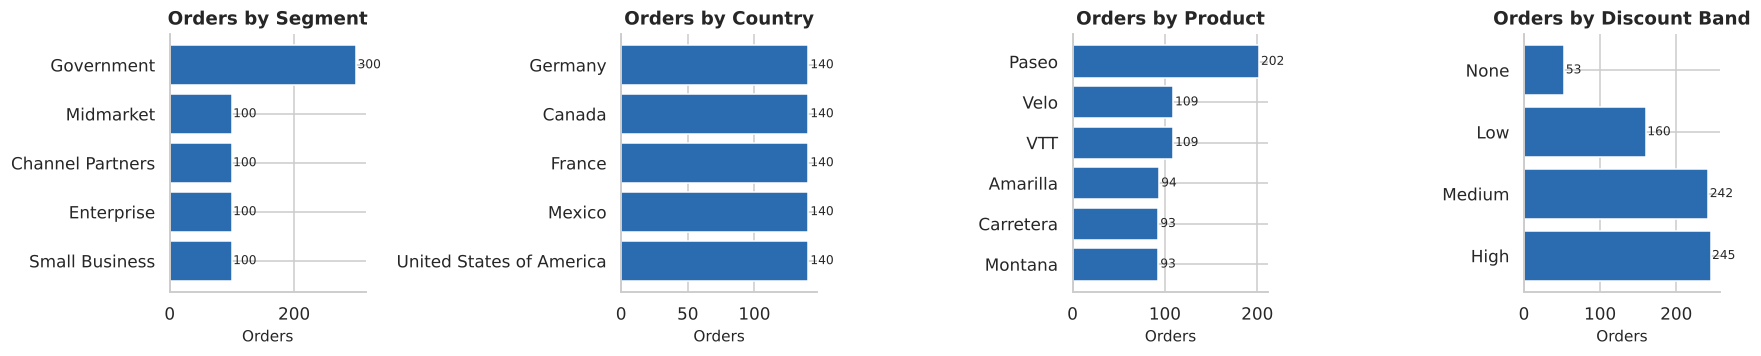

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ["Segment", "Country", "Product", "Discount Band"]):
    vc = df[col].value_counts() if col != "Discount Band" else df[col].value_counts().reindex(["None","Low","Medium","High"])
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1], color=BLUE)
    ax.set_title(f"Orders by {col}"); ax.set_xlabel("Orders")
    for i, v in enumerate(vc.values[::-1]): ax.text(v + 2, i, str(v), va="center", fontsize=8)
save("01_order_counts")

In [6]:
def perf(by):
    t = (df.groupby(by, observed=True)
           .agg(Orders=("Sales","size"), Units=("Units Sold","sum"), Sales=("Sales","sum"),
                Discounts=("Discounts","sum"), COGS=("COGS","sum"), Profit=("Profit","sum"))
           .assign(**{"Margin %": lambda x: x.Profit/x.Sales*100,
                      "Sales share %": lambda x: x.Sales/x.Sales.sum()*100,
                      "Profit share %": lambda x: x.Profit/x.Profit.sum()*100}))
    return t.sort_values("Sales", ascending=False)

by_segment, by_country = perf("Segment"), perf("Country")
by_product, by_band    = perf("Product"), perf("Discount Band")
by_year                = perf("Year")
for name, t in [("Segment", by_segment), ("Country", by_country), ("Product", by_product),
                ("Discount Band", by_band), ("Year", by_year)]:
    print(f"--- Performance by {name}"); display(t)

--- Performance by Segment


,Orders,Units,Sales,Discounts,COGS,Profit,Margin %,Sales share %,Profit share %
Segment,,,,,,,,,
Government,300,"470,673.50","52,504,260.67","3,898,805.83","41,116,087.50","11,388,173.17",21.69,44.22,67.41
Small Business,100,"153,139.00","42,427,918.50","3,513,781.50","38,284,750.00","4,143,168.50",9.77,35.74,24.52
Enterprise,100,"168,552.00","19,611,694.37","1,457,305.62","20,226,240.00","-614,545.62",-3.13,16.52,-3.64
Midmarket,100,"172,178.00","2,381,883.08","200,786.92","1,721,780.00","660,103.07",27.71,2.01,3.91
Channel Partners,100,"161,263.50","1,800,593.64","134,568.36","483,790.50","1,316,803.14",73.13,1.52,7.79


--- Performance by Country


,Orders,Units,Sales,Discounts,COGS,Profit,Margin %,Sales share %,Profit share %
Country,,,,,,,,,
United States of America,140,"232,627.50","25,029,830.16","2,239,527.83","22,034,289.50","2,995,540.67",11.97,21.08,17.73
Canada,140,"247,428.50","24,887,654.89","2,044,508.61","21,358,426.00","3,529,228.89",14.18,20.96,20.89
France,140,"240,931.00","24,354,172.27","1,727,502.22","20,573,151.50","3,781,020.78",15.53,20.51,22.38
Germany,140,"201,494.00","23,505,340.82","1,416,126.68","19,824,952.00","3,680,388.82",15.66,19.80,21.79
Mexico,140,"203,325.00","20,949,352.11","1,777,582.89","18,041,829.00","2,907,523.11",13.88,17.65,17.21


--- Performance by Product


,Orders,Units,Sales,Discounts,COGS,Profit,Margin %,Sales share %,Profit share %
Product,,,,,,,,,
Paseo,202,"338,239.50","33,011,143.95","2,600,518.05","28,213,706.00","4,797,437.95",14.53,27.80,28.40
VTT,109,"168,783.00","20,511,921.02","1,456,612.48","17,477,313.00","3,034,608.02",14.79,17.28,17.96
Velo,109,"162,424.50","18,250,059.46","1,576,709.03","15,944,067.00","2,305,992.46",12.64,15.37,13.65
Amarilla,94,"155,315.00","17,747,116.06","1,290,163.44","14,933,012.00","2,814,104.06",15.86,14.95,16.66
Montana,93,"154,198.00","15,390,801.88","1,159,032.62","13,276,047.00","2,114,754.88",13.74,12.96,12.52
Carretera,93,"146,846.00","13,815,307.88","1,122,212.61","11,988,503.00","1,826,804.89",13.22,11.64,10.81


--- Performance by Discount Band


,Orders,Units,Sales,Discounts,COGS,Profit,Margin %,Sales share %,Profit share %
Discount Band,,,,,,,,,
Medium,242,"379,698.50","38,780,430.84","3,002,546.17","33,200,908.00","5,579,522.83",14.39,32.66,33.03
High,245,"398,085.50","37,372,486.73","5,317,026.28","33,983,620.00","3,388,866.73",9.07,31.48,20.06
Low,160,"261,858.50","34,629,778.70","885,675.80","28,440,921.00","6,188,857.70",17.87,29.17,36.63
None,53,"86,163.50","7,943,654.00",0.00,"6,207,199.00","1,736,455.00",21.86,6.69,10.28


--- Performance by Year


,Orders,Units,Sales,Discounts,COGS,Profit,Margin %,Sales share %,Profit share %
Year,,,,,,,,,
2014,525,"861,132.00","92,311,094.75","7,059,716.75","79,295,857.00","13,015,237.75",14.10,77.75,77.04
2013,175,"264,674.00","26,415,255.51","2,145,531.49","22,536,791.00","3,878,464.51",14.68,22.25,22.96


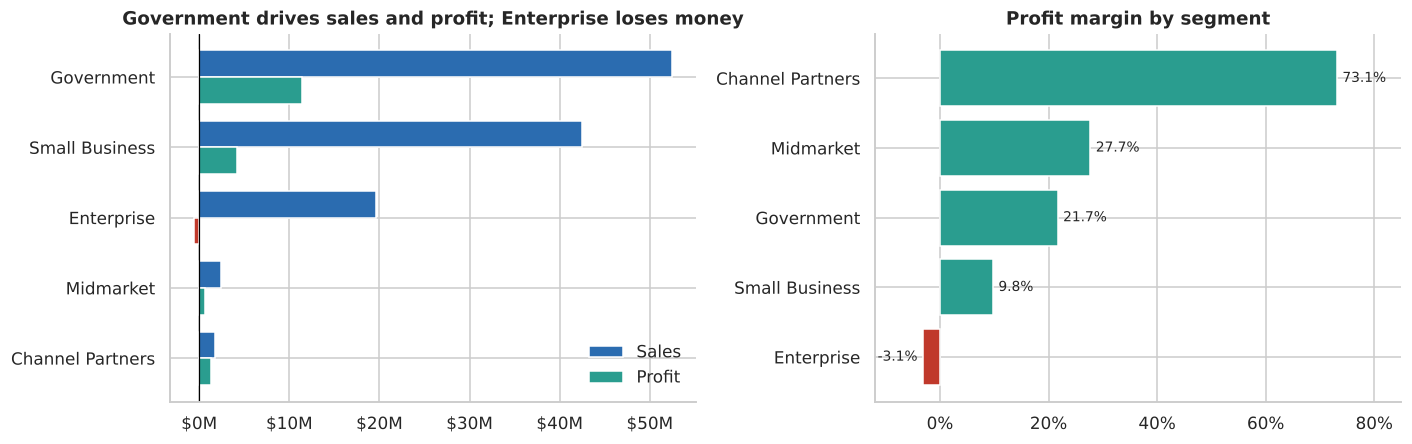

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
seg = by_segment.sort_values("Sales")
y = np.arange(len(seg)); h = 0.38
axes[0].barh(y + h/2, seg["Sales"], h, color=BLUE, label="Sales")
axes[0].barh(y - h/2, seg["Profit"], h, color=[RED if v < 0 else TEAL for v in seg["Profit"]], label="Profit")
axes[0].set_yticks(y); axes[0].set_yticklabels(seg.index); axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(money_m))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Government drives sales and profit; Enterprise loses money"); axes[0].legend(frameon=False)

m = by_segment.sort_values("Margin %")
axes[1].barh(m.index, m["Margin %"], color=[RED if v < 0 else TEAL for v in m["Margin %"]])
for i, v in enumerate(m["Margin %"]): axes[1].text(v + (1 if v >= 0 else -1), i, f"{v:.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
axes[1].set_title("Profit margin by segment"); axes[1].xaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set_xlim(-12, 85)
save("02_segment_sales_profit_margin")

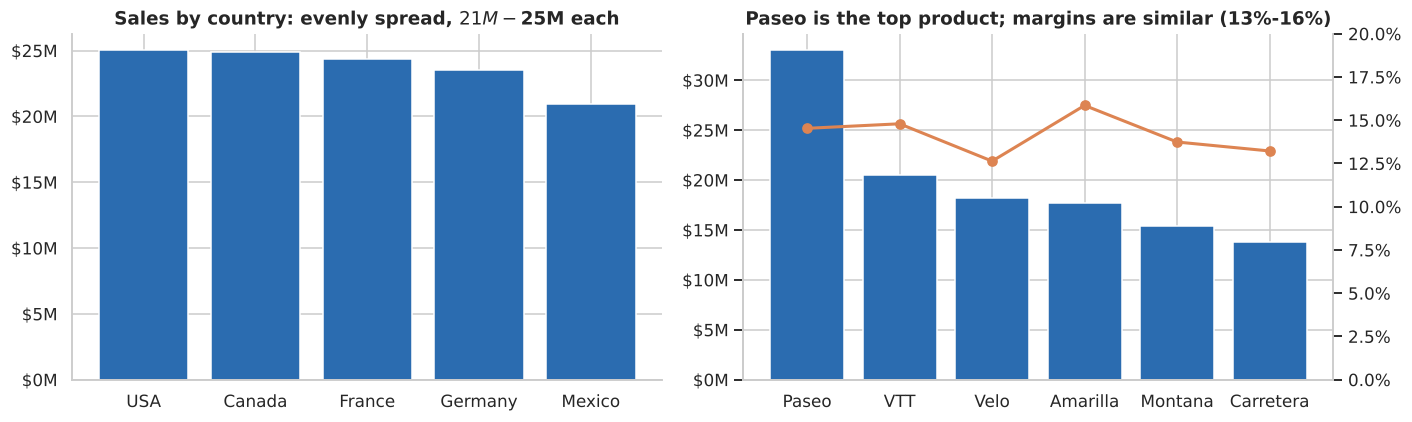

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
c = by_country.sort_values("Sales", ascending=False)
axes[0].bar(c.index.str.replace("United States of America", "USA"), c["Sales"], color=BLUE)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(money_m)); axes[0].set_title("Sales by country: evenly spread, $21M-$25M each")
p = by_product.sort_values("Sales", ascending=False)
axes[1].bar(p.index, p["Sales"], color=BLUE, label="Sales")
ax2 = axes[1].twinx(); ax2.plot(p.index, p["Margin %"], color=ORANGE, marker="o", lw=2, label="Margin %")
ax2.set_ylim(0, 20); ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.grid(False); ax2.spines["right"].set_visible(True)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(money_m)); axes[1].set_title("Paseo is the top product; margins are similar (13%-16%)")
save("03_country_product")

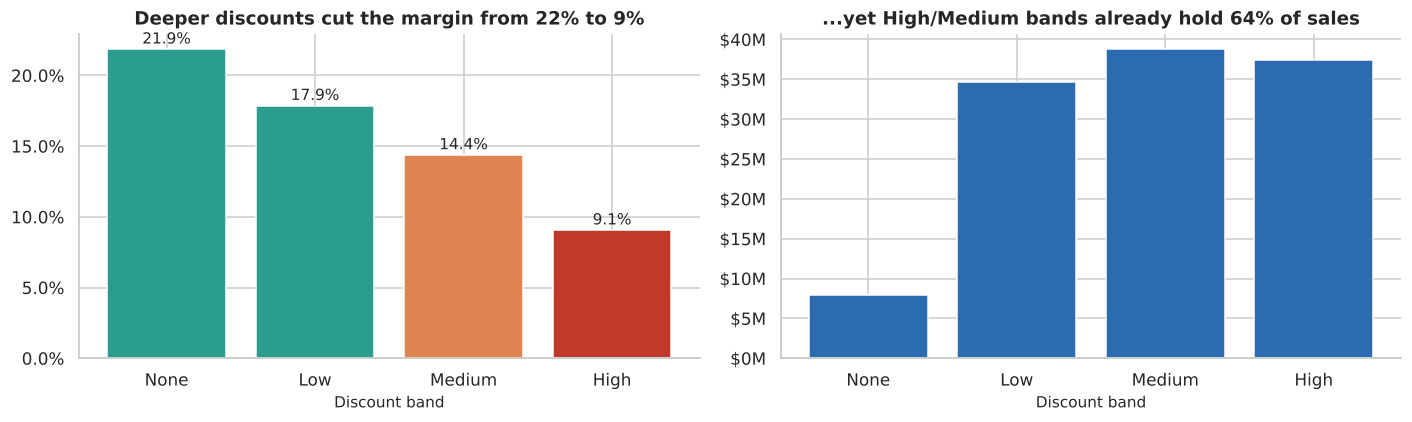

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
b = by_band.reindex(["None","Low","Medium","High"])
axes[0].bar(b.index.astype(str), b["Margin %"], color=[TEAL, TEAL, ORANGE, RED])
for i, v in enumerate(b["Margin %"]): axes[0].text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=10)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[0].set_title("Deeper discounts cut the margin from 22% to 9%")
axes[0].set_xlabel("Discount band")
axes[1].bar(b.index.astype(str), b["Sales"], color=BLUE)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(money_m)); axes[1].set_title("...yet High/Medium bands already hold 64% of sales")
axes[1].set_xlabel("Discount band")
save("04_discount_band")

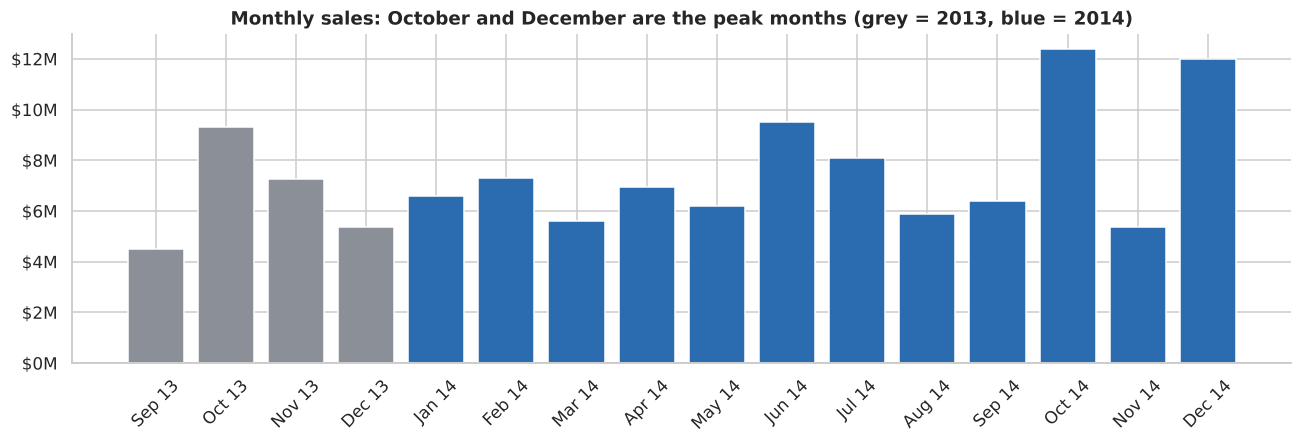

,Sales,Profit,Orders,Margin %
Month,,,,
2013-09-01,"4,484,000.03","763,603.03",35,17.03
2013-10-01,"9,295,611.10","1,657,795.10",70,17.83
2013-11-01,"7,267,203.30","765,502.30",35,10.53
2013-12-01,"5,368,441.08","691,564.08",35,12.88
2014-01-01,"6,607,761.68","814,028.68",35,12.32
2014-02-01,"7,297,531.39","1,148,547.39",35,15.74
2014-03-01,"5,586,859.87","669,866.87",35,11.99
2014-04-01,"6,964,775.07","929,984.57",35,13.35
2014-05-01,"6,210,211.06","828,640.06",35,13.34


In [10]:
monthly = (df.groupby("Month").agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Orders=("Sales","size"))
             .assign(**{"Margin %": lambda x: x.Profit/x.Sales*100}))
fig, ax = plt.subplots(figsize=(12, 4.2))
cols = [BLUE if d.year == 2014 else GREY for d in monthly.index]
ax.bar(monthly.index.strftime("%b %y"), monthly["Sales"], color=cols)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_m))
ax.set_title("Monthly sales: October and December are the peak months (grey = 2013, blue = 2014)")
plt.xticks(rotation=45)
save("05_monthly_sales")
display(monthly)

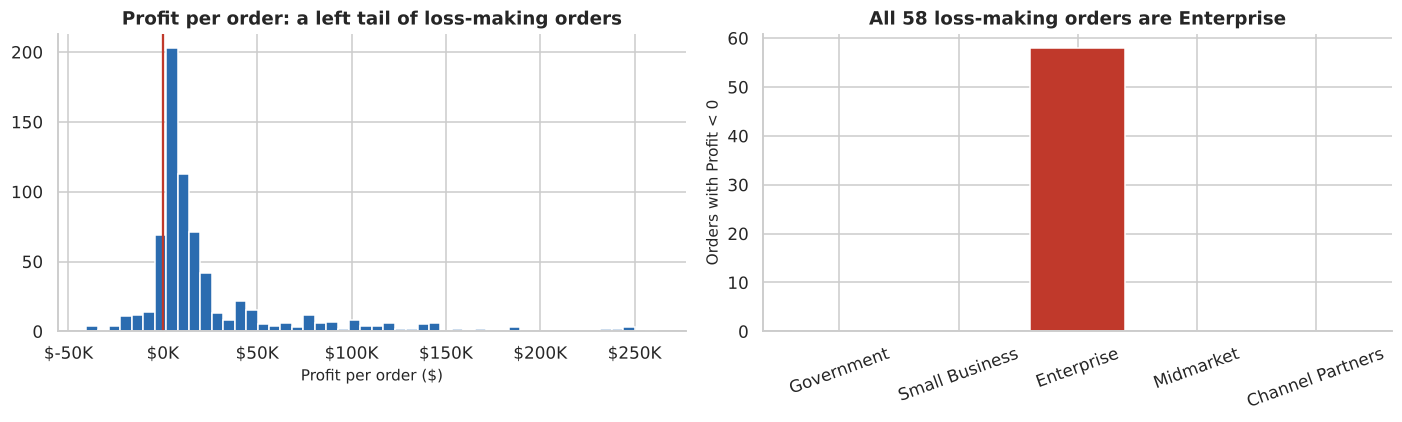

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["Profit"], bins=50, color=BLUE)
axes[0].axvline(0, color=RED, lw=1.5); axes[0].set_title("Profit per order: a left tail of loss-making orders")
axes[0].set_xlabel("Profit per order ($)"); axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(money_k))
loss = df[df["Profit"] < 0].groupby("Segment").size().reindex(by_segment.index).fillna(0)
axes[1].bar(loss.index, loss.values, color=[RED if v else GREY for v in loss.values])
axes[1].set_title(f"All {kpi['loss_orders']} loss-making orders are Enterprise"); axes[1].set_ylabel("Orders with Profit < 0")
plt.setp(axes[1].get_xticklabels(), rotation=20)
save("06_profit_distribution_losses")

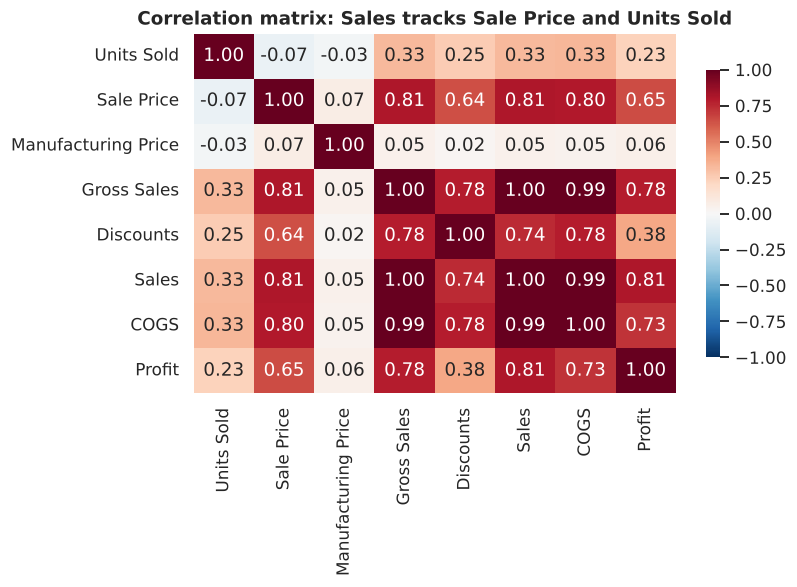

In [12]:
num = ["Units Sold","Sale Price","Manufacturing Price","Gross Sales","Discounts","Sales","COGS","Profit"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix: Sales tracks Sale Price and Units Sold")
save("07_correlation")

## 4. Analysis with SQL (SQLite) and Pandas
The cleaned table is loaded into an in-memory SQLite database. Each SQL result is cross-checked against
the equivalent Pandas calculation.

In [13]:
con = sqlite3.connect(":memory:")
sql_df = df.drop(columns=["Month"]).rename(columns=lambda c: c.replace(" %", "_pct").replace(" ", "_"))
sql_df["Date"] = sql_df["Date"].dt.strftime("%Y-%m-%d")
sql_df["Discount_Band"] = sql_df["Discount_Band"].astype(str)
sql_df.to_sql("sales", con, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql_query(sql, con)

print("Q1. Segment performance")
q1 = q('''
    SELECT Segment,
           COUNT(*)                              AS orders,
           ROUND(SUM(Sales), 0)                  AS sales,
           ROUND(SUM(Profit), 0)                 AS profit,
           ROUND(100.0 * SUM(Profit) / SUM(Sales), 2) AS margin_pct
    FROM sales GROUP BY Segment ORDER BY sales DESC''')
display(q1)

print("Q2. Top 10 Segment x Product combinations by profit")
q2 = q('''
    SELECT Segment, Product, COUNT(*) AS orders,
           ROUND(SUM(Sales), 0) AS sales, ROUND(SUM(Profit), 0) AS profit,
           ROUND(100.0 * SUM(Profit) / SUM(Sales), 1) AS margin_pct
    FROM sales GROUP BY Segment, Product ORDER BY profit DESC LIMIT 10''')
display(q2)

print("Q3. Discount band impact")
q3 = q('''
    SELECT Discount_Band, COUNT(*) AS orders, ROUND(AVG(Discount_pct), 2) AS avg_discount_pct,
           ROUND(SUM(Sales), 0) AS sales, ROUND(SUM(Profit), 0) AS profit,
           ROUND(100.0 * SUM(Profit) / SUM(Sales), 2) AS margin_pct
    FROM sales GROUP BY Discount_Band
    ORDER BY CASE Discount_Band WHEN 'None' THEN 1 WHEN 'Low' THEN 2 WHEN 'Medium' THEN 3 ELSE 4 END''')
display(q3)

print("Q4. Loss-making orders by segment and product")
q4 = q('''
    SELECT Segment, Product, COUNT(*) AS loss_orders, ROUND(SUM(Profit), 0) AS total_loss
    FROM sales WHERE Profit < 0 GROUP BY Segment, Product ORDER BY total_loss''')
display(q4)

print("Q5. Monthly sales with running total (window function)")
q5 = q('''
    SELECT substr(Date, 1, 7) AS month, ROUND(SUM(Sales), 0) AS sales,
           ROUND(SUM(SUM(Sales)) OVER (ORDER BY substr(Date, 1, 7)), 0) AS cumulative_sales
    FROM sales GROUP BY month ORDER BY month''')
display(q5)

print("Q6. Country ranking by profit, then margin")
q6 = q('''
    SELECT Country, ROUND(SUM(Sales), 0) AS sales, ROUND(SUM(Profit), 0) AS profit,
           ROUND(100.0 * SUM(Profit) / SUM(Sales), 2) AS margin_pct,
           RANK() OVER (ORDER BY SUM(Profit) DESC) AS profit_rank
    FROM sales GROUP BY Country''')
display(q6)

# cross-check SQL against Pandas
assert np.isclose(q1.set_index("Segment")["sales"], by_segment.loc[q1["Segment"], "Sales"].values, atol=1).all()
assert np.isclose(q3.set_index("Discount_Band")["profit"].values,
                  by_band.loc[["None","Low","Medium","High"], "Profit"].values, atol=1).all()
print("SQL results match the Pandas calculations.")

Q1. Segment performance


,Segment,orders,sales,profit,margin_pct
0,Government,300,"52,504,261.00","11,388,173.00",21.69
1,Small Business,100,"42,427,919.00","4,143,169.00",9.77
2,Enterprise,100,"19,611,694.00","-614,546.00",-3.13
3,Midmarket,100,"2,381,883.00","660,103.00",27.71
4,Channel Partners,100,"1,800,594.00","1,316,803.00",73.13


Q2. Top 10 Segment x Product combinations by profit


,Segment,Product,orders,sales,profit,margin_pct
0,Government,Paseo,88,"14,882,231.00","3,057,291.00",20.50
1,Government,Amarilla,42,"9,942,899.00","2,208,302.00",22.20
2,Government,VTT,46,"8,235,829.00","1,840,654.00",22.30
3,Government,Velo,46,"7,813,422.00","1,756,732.00",22.50
4,Government,Carretera,36,"6,080,944.00","1,398,994.00",23.00
5,Small Business,Paseo,26,"11,498,810.00","1,231,310.00",10.70
6,Government,Montana,42,"5,548,936.00","1,126,201.00",20.30
7,Small Business,VTT,21,"9,341,400.00","982,150.00",10.50
8,Small Business,Montana,15,"6,674,939.00","743,314.00",11.10
9,Small Business,Velo,14,"6,407,978.00","431,103.00",6.70


Q3. Discount band impact


...

Q5. Monthly sales with running total (window function)


,month,sales,cumulative_sales
0,2013-09,"4,484,000.00","4,484,000.00"
1,2013-10,"9,295,611.00","13,779,611.00"
2,2013-11,"7,267,203.00","21,046,814.00"
3,2013-12,"5,368,441.00","26,415,256.00"
4,2014-01,"6,607,762.00","33,023,017.00"
5,2014-02,"7,297,531.00","40,320,549.00"
6,2014-03,"5,586,860.00","45,907,408.00"
7,2014-04,"6,964,775.00","52,872,184.00"
8,2014-05,"6,210,211.00","59,082,395.00"
9,2014-06,"9,518,894.00","68,601,288.00"


Q6. Country ranking by profit, then margin


,Country,sales,profit,margin_pct,profit_rank
0,France,"24,354,172.00","3,781,021.00",15.53,1
1,Germany,"23,505,341.00","3,680,389.00",15.66,2
2,Canada,"24,887,655.00","3,529,229.00",14.18,3
3,United States of America,"25,029,830.00","2,995,541.00",11.97,4
4,Mexico,"20,949,352.00","2,907,523.00",13.88,5


SQL results match the Pandas calculations.


In [14]:
# Pandas: pivot of margin by segment x discount band, plus a like-for-like year comparison
pivot_margin = (df.pivot_table(index="Segment", columns="Discount Band", values=["Profit","Sales"], aggfunc="sum", observed=True)
                  .pipe(lambda t: t["Profit"] / t["Sales"] * 100))
print("Profit margin % by Segment x Discount Band"); display(pivot_margin)

# 2013 only has Sep-Dec, so compare the same four months in both years
sd = df[df["Month Number"].between(9, 12)]
like = sd.groupby("Year").agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Orders=("Sales","size"))
like["Margin %"] = like.Profit / like.Sales * 100
print("\nLike-for-like Sep-Dec comparison"); display(like)
growth = (like.loc[2014, "Sales"] / like.loc[2013, "Sales"] - 1) * 100
print(f"Sep-Dec sales growth 2014 vs 2013: {growth:.1f}%")
print(f"(Months covered: 2013 = {sorted(df[df.Year==2013]['Month Number'].unique())}, "
      f"2014 = {sorted(df[df.Year==2014]['Month Number'].unique())})")

Profit margin % by Segment x Discount Band


Discount Band,None,Low,Medium,High
Segment,,,,
Channel Partners,75.00,74.43,73.12,71.46
Enterprise,4.00,1.58,-3.03,-9.53
Government,27.01,24.59,22.17,16.93
Midmarket,33.33,31.41,28.51,23.76
Small Business,16.67,14.51,9.90,4.74



Like-for-like Sep-Dec comparison


,Sales,Profit,Orders,Margin %
Year,,,,
2013,"26,415,255.51","3,878,464.51",175,14.68
2014,"36,157,519.26","5,435,484.26",210,15.03


Sep-Dec sales growth 2014 vs 2013: 36.9%
(Months covered: 2013 = [np.int64(9), np.int64(10), np.int64(11), np.int64(12)], 2014 = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)])


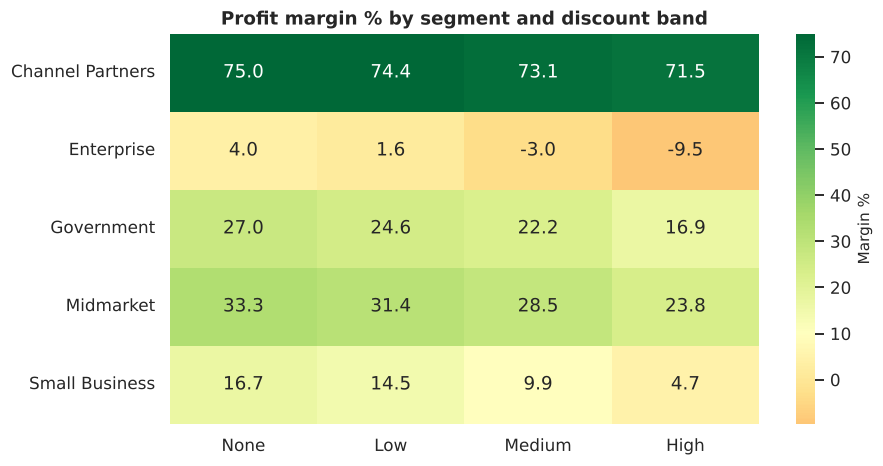

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
sns.heatmap(pivot_margin, annot=True, fmt=".1f", cmap="RdYlGn", center=10, ax=ax, cbar_kws={"label": "Margin %"})
ax.set_title("Profit margin % by segment and discount band"); ax.set_xlabel(""); ax.set_ylabel("")
save("08_margin_heatmap")

## 5. Regression model to predict sales

**Target:** `Sales` (net sales per order).
**Leakage control:** `Gross Sales`, `Discounts`, `COGS` and `Profit` are *derived from* sales, so they are excluded.
`Manufacturing Price` is dropped because it is fixed per product (redundant with `Product`).

**Features:** Units Sold, Sale Price, Discount Band, Segment, Country, Product, Month, Year.

Four models are compared on a held-out 20% test set and 5-fold cross-validation:

| Model | Idea |
|---|---|
| A. Linear regression (raw features) | Baseline: each feature enters additively |
| B. Linear regression + `Units × Price` | Adds the revenue-structure feature |
| C. Random Forest | Non-linear, learns interactions automatically |
| D. Gradient Boosting | Non-linear, boosted trees |

In [16]:
data = df.copy()
data["Discount Band"] = data["Discount Band"].astype(str)
data["Expected Gross"] = data["Units Sold"] * data["Sale Price"]   # price x volume before discount

target = "Sales"
cat = ["Discount Band", "Segment", "Country", "Product"]
num_raw = ["Units Sold", "Sale Price", "Month Number", "Year"]
num_eng = num_raw + ["Expected Gross"]

X_train_idx, X_test_idx = train_test_split(data.index, test_size=0.2, random_state=42)
y = data[target]

def make(model, numeric):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", "passthrough", numeric)])
    return Pipeline([("pre", pre), ("model", model)])

models = {
    "A. Linear (raw features)":        (make(LinearRegression(), num_raw), num_raw),
    "B. Linear + Units x Price":       (make(LinearRegression(), num_eng), num_eng),
    "C. Random Forest":                (make(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), num_eng), num_eng),
    "D. Gradient Boosting":            (make(GradientBoostingRegressor(random_state=42), num_eng), num_eng),
}

rows, fitted, preds = [], {}, {}
kf = KFold(5, shuffle=True, random_state=42)
for name, (pipe, numeric) in models.items():
    cols = cat + numeric
    pipe.fit(data.loc[X_train_idx, cols], y[X_train_idx])
    p = pipe.predict(data.loc[X_test_idx, cols])
    fitted[name], preds[name] = pipe, p
    cv = cross_val_score(pipe, data[cols], y, cv=kf, scoring="r2")
    rows.append({"Model": name,
                 "Test R2": r2_score(y[X_test_idx], p),
                 "CV R2 (mean)": cv.mean(), "CV R2 (std)": cv.std(),
                 "MAE ($)": mean_absolute_error(y[X_test_idx], p),
                 "RMSE ($)": np.sqrt(mean_squared_error(y[X_test_idx], p))})
results = pd.DataFrame(rows).set_index("Model")
display(results.style.format({"Test R2": "{:.4f}", "CV R2 (mean)": "{:.4f}", "CV R2 (std)": "{:.4f}",
                              "MAE ($)": "{:,.0f}", "RMSE ($)": "{:,.0f}"}))
best = results["Test R2"].idxmax()
print("Best model on the test set:", best)

,Test R2,CV R2 (mean),CV R2 (std),MAE ($),RMSE ($)
Model,,,,,
A. Linear (raw features),0.7643,0.7851,0.0239,"82,877","114,244"
B. Linear + Units x Price,0.9971,0.9973,0.0002,"8,804","12,733"
C. Random Forest,0.9935,0.9964,0.0016,"6,731","19,020"
D. Gradient Boosting,0.9959,0.9976,0.0011,"5,015","15,129"


Best model on the test set: B. Linear + Units x Price


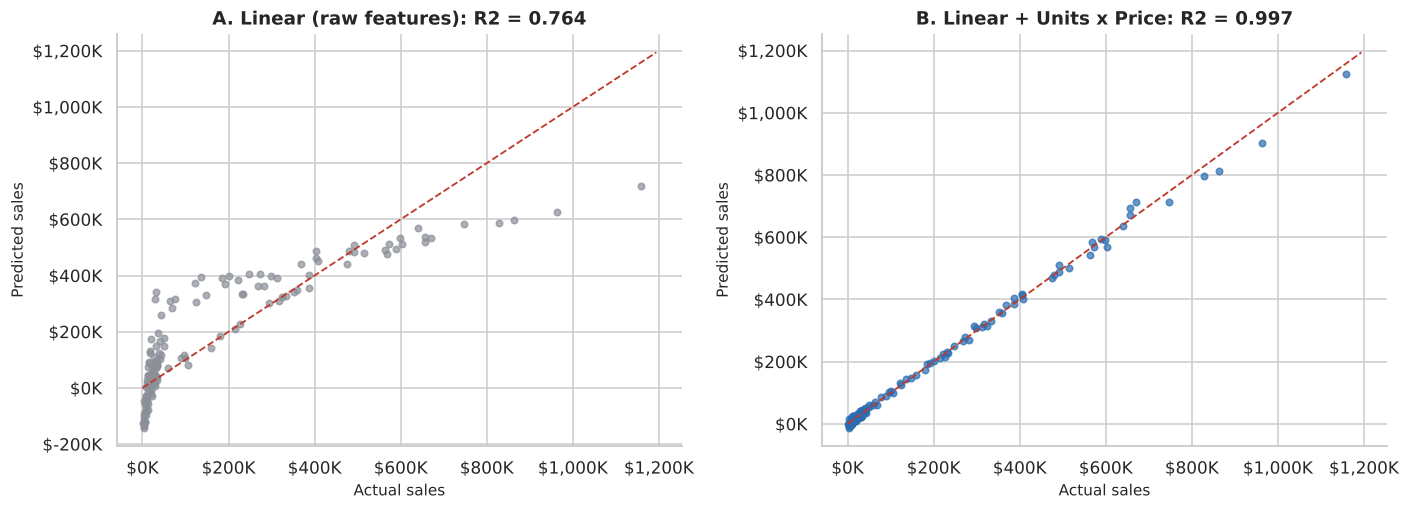

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name, color in zip(axes, ["A. Linear (raw features)", best], [GREY, BLUE]):
    ax.scatter(y[X_test_idx], preds[name], s=18, alpha=.7, color=color)
    lim = [0, max(y[X_test_idx].max(), preds[name].max()) * 1.03]
    ax.plot(lim, lim, color=RED, lw=1.2, ls="--")
    ax.set_title(f"{name}: R2 = {results.loc[name, 'Test R2']:.3f}")
    ax.set_xlabel("Actual sales"); ax.set_ylabel("Predicted sales")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(money_k)); ax.yaxis.set_major_formatter(mtick.FuncFormatter(money_k))
save("09_actual_vs_predicted")

In [18]:
# Interpretable view of the engineered linear model (OLS fitted on the training rows)
tr = data.loc[X_train_idx].rename(columns={"Expected Gross": "Expected_Gross", "Discount Band": "Band"})
ols = smf.ols("Sales ~ Expected_Gross + C(Band, Treatment('None'))", data=tr).fit()
coef = ols.summary2().tables[1][["Coef.", "Std.Err.", "P>|t|"]]
display(coef)
print(f"OLS R2 = {ols.rsquared:.4f}, adjusted R2 = {ols.rsquared_adj:.4f}")

,Coef.,Std.Err.,P>|t|
Intercept,"10,392.87","1,825.23",0.00
"C(Band, Treatment('None'))[T.High]","-19,313.11","1,997.65",0.00
"C(Band, Treatment('None'))[T.Low]",681.88,"2,095.99",0.75
"C(Band, Treatment('None'))[T.Medium]","-9,950.34","1,991.18",0.00
Expected_Gross,0.93,0.00,0.00


OLS R2 = 0.9975, adjusted R2 = 0.9975


Planning model (no volume): test R2 = 0.553, CV R2 = 0.620 +/- 0.046, MAE = $85,861


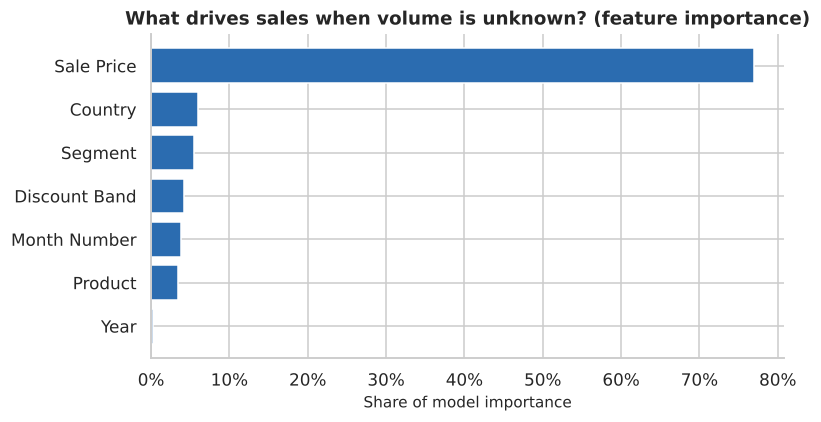

,importance
Sale Price,0.77
Country,0.06
Segment,0.05
Discount Band,0.04
Month Number,0.04
Product,0.03
Year,0.00


In [19]:
# Planning model: what drives sales WITHOUT knowing volume? (Units Sold and Units x Price removed)
plan_num = ["Sale Price", "Month Number", "Year"]
plan_cols = cat + plan_num
plan = make(GradientBoostingRegressor(random_state=42), plan_num)
plan.fit(data.loc[X_train_idx, plan_cols], y[X_train_idx])
plan_pred = plan.predict(data.loc[X_test_idx, plan_cols])
plan_cv = cross_val_score(plan, data[plan_cols], y, cv=kf, scoring="r2")
plan_r2 = r2_score(y[X_test_idx], plan_pred)
print(f"Planning model (no volume): test R2 = {plan_r2:.3f}, CV R2 = {plan_cv.mean():.3f} +/- {plan_cv.std():.3f}, "
      f"MAE = ${mean_absolute_error(y[X_test_idx], plan_pred):,.0f}")

# group one-hot columns back to their original feature
gb = plan.named_steps["model"]
names = plan.named_steps["pre"].get_feature_names_out()
imp = pd.Series(gb.feature_importances_, index=names)
def base(n):
    n = n.split("__")[1]
    for c in cat:
        if n.startswith(c.replace(" ", " ") + "_"): return c
    return n
grp = imp.groupby(base).sum().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(grp.index, grp.values * 100, color=BLUE)
ax.set_title("What drives sales when volume is unknown? (feature importance)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("Share of model importance")
save("10_feature_importance")
display(grp.sort_values(ascending=False).to_frame("importance"))

## 6. Save key metrics for the report and workbook

In [20]:
metrics = {
    "kpi": kpi,
    "by_segment": by_segment.reset_index().to_dict("records"),
    "by_country": by_country.reset_index().to_dict("records"),
    "by_product": by_product.reset_index().to_dict("records"),
    "by_band": by_band.reset_index().assign(**{"Discount Band": lambda d: d["Discount Band"].astype(str)}).to_dict("records"),
    "like_for_like": {"sales_2013": float(like.loc[2013,"Sales"]), "sales_2014": float(like.loc[2014,"Sales"]), "growth_pct": float(growth)},
    "models": results.reset_index().to_dict("records"),
    "best_model": best,
    "planning_model": {"test_r2": float(plan_r2), "cv_r2": float(plan_cv.mean()),
                       "importance": grp.sort_values(ascending=False).to_dict()},
    "ols": {"r2": float(ols.rsquared), "coef": {k: float(v) for k, v in ols.params.items()}},
    "monthly": monthly.reset_index().assign(Month=lambda d: d["Month"].dt.strftime("%Y-%m")).to_dict("records"),
}
Path("outputs").mkdir(exist_ok=True)
with open("outputs/key_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

g = by_segment
print(f"Government: {g.loc['Government','Sales share %']:.1f}% of sales, {g.loc['Government','Profit share %']:.1f}% of profit")
print(f"Enterprise: margin {g.loc['Enterprise','Margin %']:.1f}%, profit ${g.loc['Enterprise','Profit']:,.0f}")
print(f"Channel Partners: margin {g.loc['Channel Partners','Margin %']:.1f}% on only {g.loc['Channel Partners','Sales share %']:.1f}% of sales")
hb = by_band
print(f"High-discount margin {hb.loc['High','Margin %']:.1f}% vs None {hb.loc['None','Margin %']:.1f}%")
print(f"Like-for-like Sep-Dec growth: {growth:.1f}%")
print(f"High+Medium band share of sales: {hb.loc[['High','Medium'],'Sales share %'].sum():.1f}%")

Government: 44.2% of sales, 67.4% of profit
Enterprise: margin -3.1%, profit $-614,546
Channel Partners: margin 73.1% on only 1.5% of sales
High-discount margin 9.1% vs None 21.9%
Like-for-like Sep-Dec growth: 36.9%
High+Medium band share of sales: 64.1%


## 7. Findings & recommendations

**Findings**
1. **Concentration:** Government is 44% of sales and 67% of profit; Government and Small Business together make up ~80% of sales.
2. **Enterprise is unprofitable:** the segment runs a −3.1% margin (−$0.61M profit; COGS is about 103% of net sales) and *all* 58 loss-making orders belong to it (−$0.78M in total).
3. **Discounts erode profit:** margin falls from 21.9% (no discount) and 17.9% (low) to 14.4% (medium) and 9.1% (high), yet the High and Medium bands already carry 64% of sales.
4. **Geography is balanced:** USA, Canada, France and Germany each sell about $23M–$25M and Mexico about $21M, so the profit gap is a segment and pricing issue, not a country issue.
5. **Seasonality:** October and December are the peak months. 2013 only covers Sep–Dec, so the headline 3.5x jump in 2014 mostly reflects extra months; like-for-like Sep–Dec sales grew about 37%.
6. **Prediction:** with price, volume and discount band known, sales is predicted almost exactly (test R² = 0.997 for the linear model with a Units × Price feature, versus 0.76 for the raw-feature baseline). Without volume, the best planning model reaches only R² ≈ 0.55–0.62, with Sale Price the dominant driver, so *volume* is the key quantity to forecast.

**Recommendations**
1. **Fix Enterprise economics** — raise its list price, lower its unit cost or cut discounting so no order is sold below cost.
2. **Cap deep discounts** — require approval above the Medium band and shift High-band volume towards Low where possible.
3. **Protect Government, but reduce dependence on it** — it supplies two-thirds of profit.
4. **Scale Channel Partners and Midmarket** — margins of 73% and 28% on a small sales base are the best growth opportunity (worth testing before assuming they scale).
5. **Plan inventory and promotions around the Oct/Dec peaks.**
6. **Forecast units** per segment and month, then plug them into the price × discount model to forecast sales.

*Caveats:* the data covers 16 months and 700 orders, and the dataset is a standard training sample; findings describe this data, not a real business.